# 30-Day Readmission Risk: Full Training Pipeline (India Hospital Readmission 2015-2024)
**Task:** binary classification of `readmitted_30d`.
**Models:** Logistic Regression, Random Forest, fine-tuned Transformer, each **with and without** a RAG-style feature.
**RAG feature:** for every admission, retrieve the k most similar *past* admissions (by clinical-note embedding) and use their readmission rate as a feature.
**Leakage controls:** temporal split (train 2015-21 / val 2022 / test 2023-24); retrieval corpus = train+val admissions whose 30-day label was already known
at the query's admit date and (optionally) belonging to a different patient; threshold picked on validation only; `Expired` discharges and `readmitted_7d` dropped.
**Metrics:** AUC-ROC, PR-AUC, F1, Precision, Recall (threshold = max-F1 on validation).

## 0. Install (Colab). Skip lines you already have.

In [17]:
# !pip -q install kagglehub scikit-learn pandas numpy matplotlib
# !pip -q install sentence-transformers transformers torch   # only needed for EMBED_BACKEND='sbert' and the Transformer

## 1. Config

In [18]:
import os, time, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

CFG = dict(
    SEED=42,
    DATA_DIR=None,                 # folder with the 5 CSVs; None -> download with kagglehub
    OUT_DIR='outputs',
    TRAIN_END_YEAR=2021, VAL_YEAR=2022,          # test = admit year > VAL_YEAR
    # ---- RAG / retrieval ----
    EMBED_BACKEND='sbert',         # 'sbert' (semantic embeddings) or 'tfidf' (fast, CPU-only fallback)
    EMBED_MODEL='sentence-transformers/all-MiniLM-L6-v2',
    K_GRID=[10, 25, 50],           # k chosen on validation
    EXCLUDE_SAME_PATIENT=True,
    LABEL_LAG_DAYS=30,             # a neighbour label is "known" only 30 days after its discharge
    SMOOTH_M=5,                    # Bayesian shrinkage of neighbour rate toward the train prior
    # ---- classic models ----
    SEEDS=[42, 43, 44],            # RF seeds (LR is deterministic)
    LR_C_GRID=[0.01, 0.1, 1.0],
    RF_TREES=400, RF_MIN_LEAF=30,
    # ---- transformer ----
    RUN_TRANSFORMER=True,
   # TF_MODEL='distilbert-base-uncased',   # try 'emilyalsentzer/Bio_ClinicalBERT' for a clinical encoder
   # TF_MAX_LEN=160, TF_EPOCHS=3, TF_BS=64, TF_LR=5e-5, TF_SEEDS=[42],
   # TF_TRAIN_SUBSAMPLE=None,       # e.g. 30000 to speed up; auto-set on CPU
    # ---- evaluation ----
    #N_BOOT=300,
   # RUN_TRANSFORMER=True,
    TF_MODEL='emilyalsentzer/Bio_ClinicalBERT',   # Biomedical clinical encoder pre-trained on MIMIC-III
    TF_MAX_LEN=160, TF_EPOCHS=3, TF_BS=64, TF_LR=5e-5, TF_SEEDS=[42],
    TF_TRAIN_SUBSAMPLE=None,       # e.g. 30000 to speed up; auto-set on CPU
    # ---- evaluation ----
    N_BOOT=300,
)
OUT = CFG['OUT_DIR']; os.makedirs(OUT, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
set_seed(CFG['SEED'])

## 2. Load tables and build ONE ROW PER ADMISSION

In [19]:
def load_tables():
    d = CFG['DATA_DIR']
    if d is None:
        import kagglehub
        d = kagglehub.dataset_download('digutlaranjithkumar/india-hospital-readmission-dataset-20152024')
    return [pd.read_csv(os.path.join(d, f'{n}.csv')) for n in ['patients', 'admissions', 'hospitals', 'diagnoses', 'billing']]

patients, admissions, hospitals, diagnoses, billing = load_tables()
admissions['admit_date'] = pd.to_datetime(admissions.admit_date)
admissions['discharge_date'] = pd.to_datetime(admissions.discharge_date)

dx = diagnoses.sort_values(['admission_id', 'diag_rank'])
dx_agg = dx.groupby('admission_id').agg(
    primary_cat=('diag_category', 'first'), primary_dx=('diag_desc', 'first'),
    n_dx=('icd10_code', 'nunique'), dx_list=('diag_desc', lambda s: '; '.join(s))).reset_index()
hosp = hospitals.rename(columns={'name': 'hospital_name', 'state': 'hospital_state'})
pat = patients.rename(columns={'state': 'patient_state'})
df = (admissions.merge(pat, on='patient_id', how='left').merge(hosp, on='hospital_id', how='left')
      .merge(dx_agg, on='admission_id', how='left').merge(billing.drop(columns='bill_id'), on='admission_id', how='left'))
assert len(df) == len(admissions), 'join changed the row count'

# history features from the admission table itself (strictly earlier admissions of the same patient)
df = df.sort_values(['patient_id', 'admit_date', 'admission_id']).reset_index(drop=True)
g = df.groupby('patient_id')
df['hist_n_prior'] = g.cumcount()
df['hist_days_since_last'] = (df.admit_date - g.discharge_date.shift(1)).dt.days   # NaN if first admission
df['hist_has_prior'] = df.hist_days_since_last.notna().astype(int)

n0 = len(df)
df = df[df.discharge_type != 'Expired'].reset_index(drop=True)      # in-hospital deaths cannot be readmitted
print(f'dropped {n0-len(df)} Expired admissions; {len(df)} remain; readmission rate = {df.readmitted_30d.mean():.4f}')

df['insurance_type'] = df.insurance_type.fillna('Missing')
df['year'] = df.admit_date.dt.year
y = df.readmitted_30d.values.astype(int)

Using Colab cache for faster access to the 'india-hospital-readmission-dataset-20152024' dataset.
dropped 7413 Expired admissions; 112587 remain; readmission rate = 0.1262


## 3. Features, clinical-note text, temporal split

In [20]:
NUM = ['age', 'comorbidity_count', 'prev_admissions', 'los_days', 'num_procedures', 'charlson_index', 'hba1c', 'creatinine',
       'haemoglobin', 'systolic_bp', 'n_dx', 'beds', 'total_cost_inr', 'out_of_pocket_inr',
       'hist_n_prior', 'hist_days_since_last', 'hist_has_prior']
CAT = ['gender', 'insurance_type', 'bpl_card', 'admit_type', 'ward_type', 'discharge_type', 'primary_cat', 'tier', 'teaching']
RAG_COLS = ['rag_rate', 'rag_wrate', 'rag_sim_mean', 'rag_n_frac']
for c in CAT: df[c] = df[c].astype(str)

# note text: only information known at discharge, no label information
sex = df.gender.map({'M': 'male', 'F': 'female'}).fillna('patient')
df['note'] = (df.age.astype(str) + '-year-old ' + sex + ', ' + df.admit_type.str.lower() + ' admission to ' + df.ward_type.str.lower() +
              ' ward at a ' + df.tier.astype(str) + ' hospital, stay ' + df.los_days.astype(str) + ' days. Diagnoses: ' + df.dx_list + '. ' +
              'Charlson index ' + df.charlson_index.astype(str) + ', ' + df.comorbidity_count.astype(str) + ' comorbidities. ' +
              'HbA1c ' + df.hba1c.round(1).astype(str) + ', creatinine ' + df.creatinine.round(2).astype(str) +
              ', haemoglobin ' + df.haemoglobin.round(1).astype(str) + ', systolic BP ' + df.systolic_bp.round(0).astype(int).astype(str) + '. ' +
              df.num_procedures.astype(str) + ' procedures. ' + df.hist_n_prior.astype(str) + ' earlier admissions on record. ' +
              'Insurance ' + df.insurance_type + '. Discharge: ' + df.discharge_type + '.')
print(df.note.iloc[0])
notes = df.note.tolist()

yr = df.year.values
tr = np.where(yr <= CFG['TRAIN_END_YEAR'])[0]
va = np.where(yr == CFG['VAL_YEAR'])[0]
te = np.where(yr > CFG['VAL_YEAR'])[0]
prior = y[tr].mean()
print(f'train {len(tr)} ({y[tr].mean():.3f}) | val {len(va)} ({y[va].mean():.3f}) | test {len(te)} ({y[te].mean():.3f})')

25-year-old female, elective admission to hdu ward at a tier3 hospital, stay 9 days. Diagnoses: Alcoholic liver disease; Urinary tract infection. Charlson index 2, 1 comorbidities. HbA1c 6.7, creatinine 0.89, haemoglobin 12.0, systolic BP 104. 2 procedures. 0 earlier admissions on record. Insurance Private. Discharge: Recovered.
train 78751 (0.126) | val 11404 (0.130) | test 22432 (0.126)


## 4. Note embeddings

In [21]:
def embed_notes(texts):
    tag = CFG['EMBED_BACKEND'] + '_' + CFG['EMBED_MODEL'].split('/')[-1] + f'_{len(texts)}'
    cache = os.path.join(OUT, f'emb_{tag}.npy')
    if os.path.exists(cache):
        return np.load(cache)
    if CFG['EMBED_BACKEND'] == 'sbert':
        from sentence_transformers import SentenceTransformer
        E = SentenceTransformer(CFG['EMBED_MODEL']).encode(texts, batch_size=256, show_progress_bar=True,
                                                           normalize_embeddings=True, convert_to_numpy=True)
    else:   # TF-IDF + SVD (unsupervised, no labels used)
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.decomposition import TruncatedSVD
        from sklearn.preprocessing import normalize
        Xt = TfidfVectorizer(min_df=5, ngram_range=(1, 2), max_features=50000).fit_transform(texts)
        E = normalize(TruncatedSVD(128, random_state=CFG['SEED']).fit_transform(Xt))
    E = E.astype(np.float32); np.save(cache, E); return E

t0 = time.time(); E = embed_notes(notes); print('embeddings', E.shape, f'{time.time()-t0:.0f}s')

embeddings (112587, 384) 1s


## 5. RAG retrieval with time-aware, leakage-safe corpus
For query admission *q*, a corpus admission *c* is eligible only if `discharge_c + 30d < admit_q` (its readmission label was already observable)
and, if configured, `patient_c != patient_q`. Corpus = train + val admissions. Because of the date rule, a row can never retrieve itself.

In [22]:
admit_day = df.admit_date.values.astype('datetime64[D]').astype(np.int64)
disch_day = df.discharge_date.values.astype('datetime64[D]').astype(np.int64)
pid = pd.factorize(df.patient_id)[0]

def retrieve(E, corpus_idx, query_idx, kmax, chunk=512):
    C = E[corpus_idx]; c_ready = disch_day[corpus_idx] + CFG['LABEL_LAG_DAYS']; c_pid = pid[corpus_idx]
    kmax = min(kmax, len(corpus_idx))
    nbr = np.full((len(query_idx), kmax), -1, dtype=np.int64)      # global row index of neighbours (-1 = none)
    sim_out = np.full((len(query_idx), kmax), np.nan, dtype=np.float32)
    for s in range(0, len(query_idx), chunk):
        q = query_idx[s:s + chunk]
        sim = E[q] @ C.T
        elig = c_ready[None, :] < admit_day[q][:, None]
        if CFG['EXCLUDE_SAME_PATIENT']:
            elig &= c_pid[None, :] != pid[q][:, None]
        sim[~elig] = -np.inf
        part = np.argpartition(-sim, kmax - 1, axis=1)[:, :kmax]
        ps = np.take_along_axis(sim, part, 1)
        order = np.argsort(-ps, axis=1)
        part = np.take_along_axis(part, order, 1); ps = np.take_along_axis(ps, order, 1)
        ok = np.isfinite(ps)
        nbr[s:s + len(q)] = np.where(ok, corpus_idx[part], -1)
        sim_out[s:s + len(q)] = np.where(ok, ps, np.nan)
        if (s // chunk) % 20 == 0: print(f'  retrieved {s+len(q)}/{len(query_idx)}', end='\r')
    return nbr, sim_out

def rag_features(nbr, sim, k):
    nb, sm = nbr[:, :k], sim[:, :k]
    valid = nb >= 0
    lab = np.where(valid, y[np.where(valid, nb, 0)], 0).astype(float)
    n = valid.sum(1)
    rate = (lab.sum(1) + CFG['SMOOTH_M'] * prior) / (n + CFG['SMOOTH_M'])
    w = np.where(valid, np.clip(np.nan_to_num(sm), 0, None), 0.0)
    wrate = np.where(w.sum(1) > 0, (w * lab).sum(1) / np.maximum(w.sum(1), 1e-9), prior)
    sim_mean = np.where(n > 0, np.nan_to_num(sm).sum(1) / np.maximum(n, 1), 0.0)
    return pd.DataFrame({'rag_rate': rate, 'rag_wrate': wrate, 'rag_sim_mean': sim_mean, 'rag_n_frac': n / k})

corpus_idx = np.concatenate([tr, va])
all_idx = np.arange(len(df))
t0 = time.time(); NBR, SIM = retrieve(E, corpus_idx, all_idx, max(CFG['K_GRID'])); print(f'\nretrieval {time.time()-t0:.0f}s')

# --- leakage self-check on 300 random queries
rng = np.random.default_rng(0)
for qi in rng.choice(len(df), 300, replace=False):
    nb = NBR[qi][NBR[qi] >= 0]
    assert (disch_day[nb] + CFG['LABEL_LAG_DAYS'] < admit_day[qi]).all(), 'neighbour label not yet known!'
    assert qi not in nb
    if CFG['EXCLUDE_SAME_PATIENT']: assert (pid[nb] != pid[qi]).all()
    assert np.isin(nb, corpus_idx).all()
print('leakage self-check passed')


retrieval 225s
leakage self-check passed


## 6. Evaluation helpers

In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score, roc_curve

def pick_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return th[np.nanargmax(f1[:-1])]

def metrics(yt, p, thr):
    pred = (p >= thr).astype(int)
    return dict(AUC_ROC=roc_auc_score(yt, p), PR_AUC=average_precision_score(yt, p), F1=f1_score(yt, pred),
                Precision=precision_score(yt, pred, zero_division=0), Recall=recall_score(yt, pred), Threshold=thr)

RESULTS, PRED = [], {}
def record(model, rag, seed, p_va, p_te):
    thr = pick_threshold(y[va], p_va)
    m = metrics(y[te], p_te, thr); m.update(model=model, rag=rag, seed=seed); RESULTS.append(m)
    PRED.setdefault((model, rag), (p_va, p_te))
    print(f"{model:12s} rag={int(rag)} seed={seed}  AUC={m['AUC_ROC']:.4f}  PR-AUC={m['PR_AUC']:.4f}  F1={m['F1']:.4f}  P={m['Precision']:.3f}  R={m['Recall']:.3f}")

## 7. Choose k and build the RAG feature table

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_pre(num, scale):
    num_t = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler() if scale else 'passthrough')])
    cat_t = OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False)
    return ColumnTransformer([('num', num_t, num), ('cat', cat_t, CAT)])

def table(rag_df=None):
    base = df[NUM + CAT].copy()
    return base if rag_df is None else pd.concat([base, rag_df.reset_index(drop=True)], axis=1)

best_k, best_auc = None, -1
for k in CFG['K_GRID']:
    Xk = table(rag_features(NBR, SIM, k))
    pipe = Pipeline([('pre', make_pre(NUM + RAG_COLS, True)), ('clf', LogisticRegression(C=0.1, max_iter=2000, class_weight='balanced'))])
    pipe.fit(Xk.iloc[tr], y[tr]); a = roc_auc_score(y[va], pipe.predict_proba(Xk.iloc[va])[:, 1])
    print(f'k={k}: val AUC (LR + RAG) = {a:.4f}')
    if a > best_auc: best_k, best_auc = k, a
CFG['BEST_K'] = best_k; print('chosen k =', best_k)
RAG_DF = rag_features(NBR, SIM, best_k)
X_base, X_rag = table(), table(RAG_DF)
print('RAG feature alone, val AUC:', round(roc_auc_score(y[va], RAG_DF.rag_rate.values[va]), 4), '| test AUC:', round(roc_auc_score(y[te], RAG_DF.rag_rate.values[te]), 4))

k=10: val AUC (LR + RAG) = 0.7379
k=25: val AUC (LR + RAG) = 0.7379
k=50: val AUC (LR + RAG) = 0.7379
chosen k = 50
RAG feature alone, val AUC: 0.6843 | test AUC: 0.6961


## 8. Logistic Regression and Random Forest (with / without RAG)

In [25]:
def run_lr(use_rag):
    X = X_rag if use_rag else X_base; num = NUM + (RAG_COLS if use_rag else [])
    best = None
    for C in CFG['LR_C_GRID']:
        m = Pipeline([('pre', make_pre(num, True)), ('clf', LogisticRegression(C=C, max_iter=3000, class_weight='balanced'))])
        m.fit(X.iloc[tr], y[tr]); pv = m.predict_proba(X.iloc[va])[:, 1]; a = roc_auc_score(y[va], pv)
        if best is None or a > best[0]: best = (a, m, C)
    m = best[1]; record('LogReg', use_rag, 0, m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(X.iloc[te])[:, 1])

def run_rf(use_rag, seed):
    X = X_rag if use_rag else X_base; num = NUM + (RAG_COLS if use_rag else [])
    m = Pipeline([('pre', make_pre(num, False)),
                  ('clf', RandomForestClassifier(n_estimators=CFG['RF_TREES'], min_samples_leaf=CFG['RF_MIN_LEAF'], max_features='sqrt',
                                                 class_weight='balanced_subsample', n_jobs=-1, random_state=seed))])
    m.fit(X.iloc[tr], y[tr]); record('RandomForest', use_rag, seed, m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(X.iloc[te])[:, 1])
    return m

for use_rag in [False, True]:
    run_lr(use_rag)
    for s in CFG['SEEDS']:
        last_rf = run_rf(use_rag, s)

names = last_rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(last_rf.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
print('\nTop RF importances (RAG run):\n', imp.head(12).round(4))

LogReg       rag=0 seed=0  AUC=0.7543  PR-AUC=0.3571  F1=0.3844  P=0.321  R=0.479
RandomForest rag=0 seed=42  AUC=0.7496  PR-AUC=0.3361  F1=0.3741  P=0.329  R=0.433
RandomForest rag=0 seed=43  AUC=0.7490  PR-AUC=0.3353  F1=0.3710  P=0.267  R=0.606
RandomForest rag=0 seed=44  AUC=0.7491  PR-AUC=0.3358  F1=0.3765  P=0.315  R=0.469
LogReg       rag=1 seed=0  AUC=0.7543  PR-AUC=0.3572  F1=0.3847  P=0.321  R=0.479
RandomForest rag=1 seed=42  AUC=0.7480  PR-AUC=0.3345  F1=0.3802  P=0.286  R=0.569
RandomForest rag=1 seed=43  AUC=0.7478  PR-AUC=0.3338  F1=0.3766  P=0.295  R=0.520
RandomForest rag=1 seed=44  AUC=0.7489  PR-AUC=0.3349  F1=0.3812  P=0.291  R=0.552

Top RF importances (RAG run):
 num__rag_wrate            0.0972
num__los_days             0.0748
num__age                  0.0644
num__total_cost_inr       0.0640
num__rag_rate             0.0603
num__charlson_index       0.0553
num__comorbidity_count    0.0548
num__n_dx                 0.0513
num__rag_sim_mean         0.0480
num__haem

## 9. Fine-tuned Transformer (note text; RAG scalars concatenated to the pooled embedding)

In [26]:
def run_transformer(use_rag, seed):
    import torch, torch.nn as nn
    from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(CFG['TF_MODEL'])
    if 'IDS' not in globals() or globals().get('IDS_MODEL') != CFG['TF_MODEL']:
        globals()['IDS'] = tok(notes, truncation=True, max_length=CFG['TF_MAX_LEN'])['input_ids']; globals()['IDS_MODEL'] = CFG['TF_MODEL']
    ids = globals()['IDS']
    extra = RAG_DF[RAG_COLS].values.astype(np.float32) if use_rag else None
    if use_rag:
        mu, sd = extra[tr].mean(0), extra[tr].std(0) + 1e-6; extra = (extra - mu) / sd
    tr_i = tr
    sub = CFG['TF_TRAIN_SUBSAMPLE']
    if dev == 'cpu' and sub is None:
        sub = 20000; print('No GPU detected: subsampling train to 20000 rows and using 1 epoch for a feasible run.')
    if sub and sub < len(tr_i): tr_i = np.random.default_rng(seed).choice(tr, sub, replace=False)
    epochs = CFG['TF_EPOCHS'] if dev == 'cuda' else 1

    class Net(nn.Module):
        def __init__(s, n_extra):
            super().__init__(); s.enc = AutoModel.from_pretrained(CFG['TF_MODEL']); h = s.enc.config.hidden_size
            s.drop = nn.Dropout(0.1); s.head = nn.Linear(h + n_extra, 1)
        def forward(s, x, m, e=None):
            o = s.enc(input_ids=x, attention_mask=m).last_hidden_state
            mm = m.unsqueeze(-1).to(o.dtype); pooled = (o * mm).sum(1) / mm.sum(1).clamp(min=1)
            if e is not None: pooled = torch.cat([pooled, e.to(pooled.dtype)], 1)
            return s.head(s.drop(pooled)).squeeze(-1)

    def batches(idx, bs, shuffle):
        idx = np.array(idx)
        if shuffle: idx = np.random.permutation(idx)
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]
            enc = tok.pad({'input_ids': [ids[i] for i in b]}, return_tensors='pt')
            e = torch.from_numpy(extra[b]).to(dev) if use_rag else None
            yield b, enc['input_ids'].to(dev), enc['attention_mask'].to(dev), e

    @torch.no_grad()
    def predict(idx):
        net.eval(); out = []
        for b, x, m, e in batches(idx, 256, False):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(dev == 'cuda')):
                out.append(torch.sigmoid(net(x, m, e).float()).cpu().numpy())
        return np.concatenate(out)

    net = Net(len(RAG_COLS) if use_rag else 0).to(dev)
    pos_w = torch.tensor(float((1 - y[tr_i].mean()) / y[tr_i].mean()), dtype=torch.float32, device=dev)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(net.parameters(), lr=CFG['TF_LR'], weight_decay=0.01)
    steps = epochs * int(np.ceil(len(tr_i) / CFG['TF_BS']))
    sch = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.cuda.amp.GradScaler(enabled=(dev == 'cuda'))
    best_auc, best_state = -1, None
    for ep in range(epochs):
        net.train(); t0 = time.time(); tot = 0
        for b, x, m, e in batches(tr_i, CFG['TF_BS'], True):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(dev == 'cuda')):
                logit = net(x, m, e)
            loss = lossf(logit.float(), torch.from_numpy(y[b]).float().to(dev))
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step(); tot += loss.item() * len(b)
        pv = predict(va); a = roc_auc_score(y[va], pv)
        print(f'  [TF rag={int(use_rag)} seed={seed}] epoch {ep+1}/{epochs} loss={tot/len(tr_i):.4f} val AUC={a:.4f} ({time.time()-t0:.0f}s)')
        if a > best_auc: best_auc, best_state = a, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    record('Transformer', use_rag, seed, predict(va), predict(te))
    del net, opt
    if dev == 'cuda': torch.cuda.empty_cache()

if CFG['RUN_TRANSFORMER']:
    for use_rag in [False, True]:
        for s in CFG['TF_SEEDS']:
            run_transformer(use_rag, s)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

model.safetensors: downloading bytes:           |  0.00B            

  [TF rag=0 seed=42] epoch 1/3 loss=1.0805 val AUC=0.7293 (486s)
  [TF rag=0 seed=42] epoch 2/3 loss=1.0483 val AUC=0.7347 (486s)
  [TF rag=0 seed=42] epoch 3/3 loss=1.0317 val AUC=0.7346 (485s)
Transformer  rag=0 seed=42  AUC=0.7447  PR-AUC=0.3349  F1=0.3681  P=0.341  R=0.399


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [TF rag=1 seed=42] epoch 1/3 loss=1.0821 val AUC=0.7291 (486s)
  [TF rag=1 seed=42] epoch 2/3 loss=1.0510 val AUC=0.7372 (485s)
  [TF rag=1 seed=42] epoch 3/3 loss=1.0346 val AUC=0.7373 (485s)
Transformer  rag=1 seed=42  AUC=0.7486  PR-AUC=0.3383  F1=0.3734  P=0.338  R=0.418


## 10. Results table, paired patient-cluster bootstrap, plots

                   AUC_ROC          PR_AUC              F1         Precision  \
                      mean     std    mean     std    mean     std      mean   
model        rag                                                               
LogReg       False  0.7543     NaN  0.3571     NaN  0.3844     NaN    0.3210   
             True   0.7543     NaN  0.3572     NaN  0.3847     NaN    0.3213   
RandomForest False  0.7492  0.0003  0.3357  0.0004  0.3738  0.0028    0.3037   
             True   0.7482  0.0006  0.3344  0.0005  0.3793  0.0024    0.2906   
Transformer  False  0.7447     NaN  0.3349     NaN  0.3681     NaN    0.3413   
             True   0.7486     NaN  0.3383     NaN  0.3734     NaN    0.3376   

                            Recall          
                       std    mean     std  
model        rag                            
LogReg       False     NaN  0.4789     NaN  
             True      NaN  0.4792     NaN  
RandomForest False  0.0325  0.5025  0.0916  
         

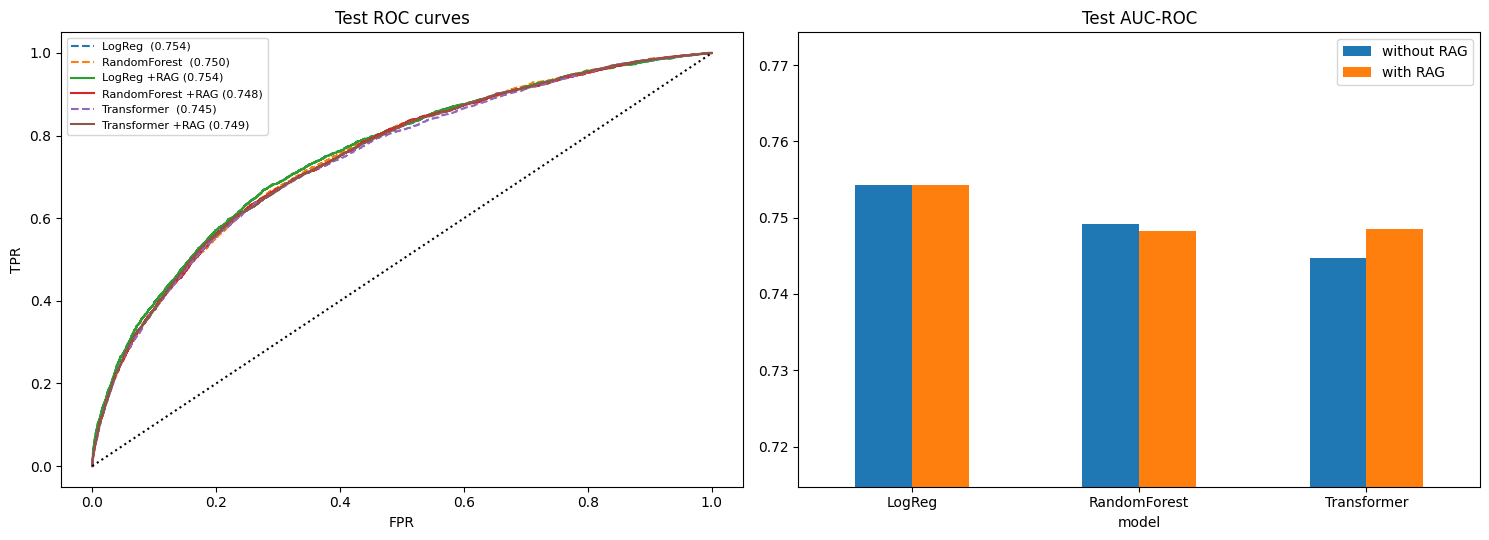

saved to outputs


In [27]:
R = pd.DataFrame(RESULTS)
R.to_csv(os.path.join(OUT, 'results_raw.csv'), index=False)
cols = ['AUC_ROC', 'PR_AUC', 'F1', 'Precision', 'Recall']
S = R.groupby(['model', 'rag'])[cols].agg(['mean', 'std']).round(4)
S.to_csv(os.path.join(OUT, 'results_summary.csv')); display(S) if 'display' in globals() else print(S)

# paired bootstrap of AUC(with RAG) - AUC(without RAG) on the test set, resampling PATIENTS
te_pid = pid[te]; groups = {p: np.where(te_pid == p)[0] for p in np.unique(te_pid)}; keys = np.array(list(groups))
rng = np.random.default_rng(1); delta = {}
for model in sorted(R.model.unique()):
    p0, p1 = PRED[(model, False)][1], PRED[(model, True)][1]; ds = []
    for _ in range(CFG['N_BOOT']):
        idx = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
        if y[te][idx].min() == y[te][idx].max(): continue
        ds.append(roc_auc_score(y[te][idx], p1[idx]) - roc_auc_score(y[te][idx], p0[idx]))
    delta[model] = dict(mean_delta_AUC=np.mean(ds), ci_low=np.percentile(ds, 2.5), ci_high=np.percentile(ds, 97.5),
                        significant=bool(np.percentile(ds, 2.5) > 0 or np.percentile(ds, 97.5) < 0))
D = pd.DataFrame(delta).T; D.to_csv(os.path.join(OUT, 'rag_effect_bootstrap.csv')); print('\nEffect of the RAG feature on test AUC (95% CI):\n', D.round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for (model, rag), (pv, pt) in PRED.items():
    fpr, tpr, _ = roc_curve(y[te], pt); ax[0].plot(fpr, tpr, ls='-' if rag else '--', label=f"{model} {'+RAG' if rag else ''} ({roc_auc_score(y[te], pt):.3f})")
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set(title='Test ROC curves', xlabel='FPR', ylabel='TPR'); ax[0].legend(fontsize=8)
M = R.groupby(['model', 'rag']).AUC_ROC.mean().unstack(); M.columns = ['without RAG', 'with RAG']; M.plot.bar(ax=ax[1], rot=0)
ax[1].set(title='Test AUC-ROC', ylim=(max(0.5, M.values.min() - 0.03), M.values.max() + 0.02)); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'results.png'), dpi=150); plt.show()

pd.DataFrame({'admission_id': df.admission_id.values[te], 'y': y[te],
              **{f"{m}_{'rag' if r else 'base'}": PRED[(m, r)][1] for (m, r) in PRED}}).to_csv(os.path.join(OUT, 'test_predictions.csv'), index=False)
json.dump({k: (v if not isinstance(v, np.generic) else v.item()) for k, v in CFG.items()}, open(os.path.join(OUT, 'config_used.json'), 'w'), indent=1)
print('saved to', OUT)